# Joint Sensor + Gateway Placement (NSGA-II)

This notebook selects **which candidate sites get sensor nodes (M of them)** and **which get LoRaWAN gateways (K of them)** in a single multi-objective search. Both M and K are set in the Configuration cell.

**Decision variables.** Two binary vectors over the N candidate sites: `s` (sensor sites, exactly M ones) and `g` (gateway sites, exactly K ones). Custom operators keep these counts exact, so no population is wasted on infeasible solutions.

**Objectives (all minimized internally):**

| # | Objective | Meaning |
|---|-----------|---------|
| f1 | `-sum_{i in S} w_i * C_i` | Priority-weighted **connected** monitoring. `C_i = 1` if sensor i has a link with reliability above the threshold to at least one selected gateway. `w_i` are the hotspot-sharpened weights from the paper (Eq. 7). |
| f2 | `mean_over_all_sites min_{j in S} D_ij` | **Representativeness error.** Every candidate site is "represented" by its nearest selected sensor. `D_ij` blends geographic distance and difference in predicted PM2.5. Prevents all sensors from clustering at hotspots. |
| f3 | `mean_{i in S} SF_i` | Average spreading factor of the selected sensors, where `SF_i` is the lowest SF over gateways with a link above the reliability threshold (penalty if none). Same threshold as f1, so coverage and SF are consistent. |

**Constraints:** exactly M sensors, exactly K gateways, and (optionally) no site that hosts both.

**Radio-model uncertainty (delta).** If `link_mean_rssi_matrix.csv` is available, the reliability and SF matrices are recomputed in closed form for any systematic RSSI offset `DELTA_DB` (i.i.d. Gaussian shadowing, which matches your Monte Carlo in expectation). To produce that file, add this line to the candidate-locations notebook right after `rssi_mean_gpu` is computed:

```python
pd.DataFrame(cp.asnumpy(rssi_mean_gpu), index=node_ids, columns=node_ids).to_csv(BASE_PATH + "link_mean_rssi_matrix.csv")
```

Without that file the notebook runs at `DELTA_DB = 0` using the saved matrices.

In [ ]:
# @title
!pip install -q pymoo contextily
# Optional GPU backend (the notebook falls back to NumPy if CuPy / a GPU is not available):
# !pip install -q cupy-cuda12x

In [ ]:
# @title Configuration
BASE_PATH = "/content/drive/MyDrive/Capstone/LoRa Placement/"
REL_PATH       = BASE_PATH + "link_reliability_matrix_gpu_realistic.csv"
SF_PATH        = BASE_PATH + "link_average_sf_matrix_gpu_realistic.csv"
LOC_PATH       = BASE_PATH + "candidate_locations_with_pm.csv"
MEAN_RSSI_PATH = BASE_PATH + "link_mean_rssi_matrix.csv"     # optional, enables DELTA_DB != 0

# ---- Budgets: choose how many sensors and gateways to place ----
NUM_SENSORS  = 15      # M
NUM_GATEWAYS = 5       # K
ALLOW_COLOCATION = False   # True: a site may host both a sensor and a gateway

# ---- Radio model ----
DELTA_DB = -12.4                 # systematic RSSI offset for the main run (e.g. -12.4 for the field-calibrated gap)
RELIABILITY_THRESHOLD = 0.99   # a link counts as "connected" above this reliability
SHADOWING_SIGMA_DB = 8.0
SF_PENALTY = 13.0              # SF assigned to a sensor with no reliable gateway (worse than SF12)

# ---- Monitoring priority / representativeness ----
PM_COL = None                  # None = auto-detect the predicted-PM column in the locations CSV
HOTSPOT_QUANTILE = 0.75        # top quartile of predicted PM = hotspot
HOTSPOT_GAMMA = 4.0            # hotspot weight boost (Eq. 7 of the paper)
GEO_WEIGHT = 0.7               # D_ij = GEO_WEIGHT * geo_dist + (1 - GEO_WEIGHT) * |PM_i - PM_j| (both normalized)

# ---- NSGA-II ----
POPULATION_SIZE = 500
GENERATIONS = 200
SEED = 42
SELECTION_WEIGHTS = (1.0, 1.0, 1.0)   # compromise pick from the Pareto front; larger = that objective matters more

# ---- Optional extras ----
RUN_BASELINES = True
RUN_DELTA_SWEEP = True
RUN_BUDGET_SWEEP = True
USE_HOTSPOT_PROB = True    # weight sites by the probability of being a hotspot (needs the hotspot_prob column)
DELTA_REF = -12.4
DELTA_LIST = [0, -5, -10, -12.4, -15, -20]
K_LIST = [3, 4, 5, 6, 8, 10]
M_LIST = [5, 10, 15, 20, 30, 50, 70, 80]
SWEEP_POP, SWEEP_GENS = 500, 200

In [ ]:
# @title Imports, backend, data loading
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import ndtr
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception:
    pass

try:
    import cupy as cp
    cp.cuda.runtime.getDeviceCount()
    _a = cp.ones((4, 4), dtype=cp.float32)
    float((_a @ _a).sum())
    float(cp.where(_a > 0, _a, 0.0).min(axis=1).sum())
    xp, GPU = cp, True
except Exception as e:
    print("GPU backend unavailable, falling back to NumPy:", type(e).__name__, str(e)[:120])
    cp, xp, GPU = None, np, False
print("Backend:", "CuPy (GPU)" if GPU else "NumPy (CPU)")

def to_np(a):
    return a.get() if (GPU and isinstance(a, cp.ndarray)) else np.asarray(a)

from pymoo.core.problem import Problem
from pymoo.core.sampling import Sampling
from pymoo.core.crossover import Crossover
from pymoo.core.mutation import Mutation
from pymoo.core.callback import Callback
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize
from pymoo.termination import get_termination
from pymoo.indicators.hv import HV

# ---------- link matrices saved by the radio-simulation notebook ----------
rel_df = pd.read_csv(REL_PATH, index_col=0)
sf_df  = pd.read_csv(SF_PATH,  index_col=0)
NODE_IDS = rel_df.index.astype(str).tolist()
N = len(NODE_IDS)
R_RAW = rel_df.values.astype(np.float32)
F_RAW = sf_df.values.astype(np.float32)

# ---------- candidate locations + predicted PM2.5 ----------
loc = pd.read_csv(LOC_PATH)
loc["id"] = loc["id"].astype(str)
loc = loc.set_index("id").loc[NODE_IDS].reset_index()

def detect_pm_column(df):
    if PM_COL:
        return PM_COL
    cands = [c for c in df.columns if "pm" in c.lower() and pd.api.types.is_numeric_dtype(df[c])]
    if not cands:
        raise ValueError("No numeric PM column found; set PM_COL in the configuration cell.")
    for key in ("pred", "2_5", "2.5", "25"):
        for c in cands:
            if key in c.lower():
                return c
    return cands[0]

PM_NAME = detect_pm_column(loc)
PM  = loc[PM_NAME].values.astype(float)
LAT = loc["latitude"].values.astype(float)
LON = loc["longitude"].values.astype(float)
print(f"N = {N} candidate sites | PM column = '{PM_NAME}' | PM range {PM.min():.1f} to {PM.max():.1f} (CV = {PM.std()/PM.mean():.3f})")

# ---------- config sanity ----------
M, K = int(NUM_SENSORS), int(NUM_GATEWAYS)
assert 1 <= M <= N and 1 <= K <= N, "NUM_SENSORS / NUM_GATEWAYS must be between 1 and N"
if not ALLOW_COLOCATION:
    assert M + K <= N, "Without co-location you need NUM_SENSORS + NUM_GATEWAYS <= N"

# ---------- priority weights (paper Eq. 7), geography, representativeness distance ----------
PM_Q   = np.quantile(PM, HOTSPOT_QUANTILE)
IS_HOT = PM >= PM_Q                                   # hard hotspot flag, still used for reporting
if USE_HOTSPOT_PROB and "hotspot_prob" in loc.columns:
    _raw_w = 1.0 + HOTSPOT_GAMMA * loc["hotspot_prob"].values.astype(float)
    print("Priority weights use hotspot_prob (probability of being a hotspot across parameter draws)")
else:
    _raw_w = 1.0 + HOTSPOT_GAMMA * IS_HOT
W_NP   = _raw_w / _raw_w.sum()

_lat0 = np.deg2rad(LAT.mean())
_x = 6371000.0 * np.deg2rad(LON) * np.cos(_lat0)
_y = 6371000.0 * np.deg2rad(LAT)
DGEO = np.hypot(_x[:, None] - _x[None, :], _y[:, None] - _y[None, :])
_pm_range = (PM.max() - PM.min()) + 1e-9
D_NP = GEO_WEIGHT * DGEO / DGEO.max() + (1.0 - GEO_WEIGHT) * np.abs(PM[:, None] - PM[None, :]) / _pm_range
print(f"Hotspot threshold (Q{int(HOTSPOT_QUANTILE*100)}) = {PM_Q:.2f}; hotspot sites = {int(IS_HOT.sum())}")

Mounted at /content/drive
Backend: CuPy (GPU)
N = 99 candidate sites | PM column = 'predicted_pm' | PM range 23.8 to 39.2 (CV = 0.085)
Priority weights use hotspot_prob (probability of being a hotspot across parameter draws)
Hotspot threshold (Q75) = 35.60; hotspot sites = 25


In [ ]:
# @title Link matrices under a radio-model offset (closed form) and evaluation context
SENS = {7: -123.0, 8: -126.0, 9: -129.0, 10: -132.0, 11: -134.5, 12: -137.0}

def closed_form_RF(mean_rssi, delta, sigma):
    # Reliability and mean SF for i.i.d. Gaussian shadowing, matching the Monte Carlo in expectation.
    mu = mean_rssi + delta
    p_ge = {sf: ndtr((mu - SENS[sf]) / sigma) for sf in SENS}        # P(RSSI > sensitivity_sf)
    R = p_ge[12]
    pk = {7: p_ge[7]}
    for sf in range(8, 13):
        pk[sf] = p_ge[sf] - p_ge[sf - 1]                             # lowest feasible SF is sf
    F = sum(sf * pk[sf] for sf in pk) / np.maximum(R, 1e-12)
    F = np.where(R < 1e-9, 0.0, F)
    return R.astype(np.float32), F.astype(np.float32)

HAVE_RSSI = os.path.exists(MEAN_RSSI_PATH)
if HAVE_RSSI:
    _mu_df = pd.read_csv(MEAN_RSSI_PATH, index_col=0)
    _mu_df.index, _mu_df.columns = _mu_df.index.astype(str), _mu_df.columns.astype(str)
    MEAN_RSSI = _mu_df.loc[NODE_IDS, NODE_IDS].values.astype(np.float64)
    _R0, _F0 = closed_form_RF(MEAN_RSSI, 0.0, SHADOWING_SIGMA_DB)
    _off = ~np.eye(N, dtype=bool)
    print(f"Mean-RSSI file found. Closed form vs saved Monte Carlo at delta=0: "
          f"max |dR| = {np.abs(_R0 - R_RAW)[_off].max():.4f}, mean |dR| = {np.abs(_R0 - R_RAW)[_off].mean():.5f}")
else:
    print("No link_mean_rssi_matrix.csv found: only DELTA_DB = 0 is available (see the first cell for the one-line patch).")

def get_matrices(delta):
    if HAVE_RSSI:
        return closed_form_RF(MEAN_RSSI, delta, SHADOWING_SIGMA_DB)
    if abs(delta) < 1e-9:
        return R_RAW.copy(), F_RAW.copy()
    raise FileNotFoundError("delta != 0 needs link_mean_rssi_matrix.csv (see the first cell for the patch).")

def make_context(delta=0.0):
    R, F = get_matrices(delta)
    ROK = R > RELIABILITY_THRESHOLD
    np.fill_diagonal(ROK, True)                       # a co-located sensor/gateway pair is trivially connected
    FEFF = np.where(ROK, F, SF_PENALTY).astype(np.float32)
    np.fill_diagonal(FEFF, 7.0)
    return dict(delta=float(delta), R=R, ROK_NP=ROK, FEFF_NP=FEFF,
                ROK=xp.asarray(ROK.astype(np.float32)), FEFF=xp.asarray(FEFF),
                W=xp.asarray(W_NP.astype(np.float32)), D=xp.asarray(D_NP.astype(np.float32)))

def evaluate_batch(ctx, S, G):
    # S, G: (P, N) boolean arrays of sensor / gateway choices. Returns objectives (P, 3) and covered fraction (P,).
    S = xp.asarray(S, dtype=xp.bool_)
    G = xp.asarray(G, dtype=xp.bool_)
    ST, GT = S.T, G.T                                                   # (N, P)
    covered = (ctx["ROK"] @ GT.astype(xp.float32)) > 0.5                # (N, P): sensor i has a reliable gateway
    sel_cov = ST & covered
    wcov = (ctx["W"][:, None] * sel_cov).sum(axis=0)                    # priority-weighted connected sensors

    Fm = xp.where(GT[None, :, :], ctx["FEFF"][:, :, None], SF_PENALTY)  # (N, N, P)
    best_sf = Fm.min(axis=1)                                            # (N, P)
    n_s = ST.sum(axis=0)
    sf_mean = (best_sf * ST).sum(axis=0) / n_s

    Dm = xp.where(ST[None, :, :], ctx["D"][:, :, None], 9.0)            # (N, N, P): site i vs selected sensor j
    rep = Dm.min(axis=1).mean(axis=0)

    F = xp.stack([-wcov, rep, sf_mean], axis=1)
    cov_frac = sel_cov.sum(axis=0) / n_s
    return to_np(F).astype(np.float64), to_np(cov_frac)

print("Evaluation function ready.")

Mean-RSSI file found. Closed form vs saved Monte Carlo at delta=0: max |dR| = 0.0068, mean |dR| = 0.00055
Evaluation function ready.


In [ ]:
# @title NSGA-II problem and cardinality-preserving operators
def _repair_overlap(s, g, rng):
    ov = np.flatnonzero(s & g)
    if len(ov) == 0:
        return g
    free = np.flatnonzero(~s & ~g)
    rng.shuffle(free)
    for t, j in enumerate(ov):
        g[j] = False
        g[free[t]] = True
    return g

def _cross_block(a, b, k, rng):
    child = a & b
    diff = np.flatnonzero(a ^ b)
    need = k - int(child.sum())
    if need > 0:
        child[rng.choice(diff, need, replace=False)] = True
    return child

def _swap_one(blk, other, allow, rng):
    ones = np.flatnonzero(blk)
    zero_mask = ~blk if allow else (~blk & ~other)
    zeros = np.flatnonzero(zero_mask)
    if len(ones) == 0 or len(zeros) == 0:
        return
    blk[rng.choice(ones)] = False
    blk[rng.choice(zeros)] = True

class CardinalitySampling(Sampling):
    def __init__(self, n, m, k, allow, seed=0):
        super().__init__()
        self.n, self.m, self.k, self.allow = n, m, k, allow
        self.rng = np.random.default_rng(seed)
    def _do(self, problem, n_samples, *args, **kwargs):
        n, X = self.n, np.zeros((n_samples, 2 * self.n), dtype=bool)
        for r in range(n_samples):
            s_idx = self.rng.choice(n, self.m, replace=False)
            X[r, s_idx] = True
            pool = np.arange(n) if self.allow else np.setdiff1d(np.arange(n), s_idx)
            X[r, n + self.rng.choice(pool, self.k, replace=False)] = True
        return X

class CardinalityCrossover(Crossover):
    def __init__(self, n, m, k, allow, seed=0, **kwargs):
        super().__init__(2, 2, **kwargs)
        self.n, self.m, self.k, self.allow = n, m, k, allow
        self.rng = np.random.default_rng(seed)
    def _do(self, problem, X, *args, **kwargs):
        n = self.n
        _, n_matings, _ = X.shape
        Y = np.zeros((2, n_matings, 2 * n), dtype=bool)
        for q in range(n_matings):
            a, b = X[0, q].astype(bool), X[1, q].astype(bool)
            for c in range(2):
                s = _cross_block(a[:n], b[:n], self.m, self.rng)
                g = _cross_block(a[n:], b[n:], self.k, self.rng)
                if not self.allow:
                    g = _repair_overlap(s, g, self.rng)
                Y[c, q, :n], Y[c, q, n:] = s, g
        return Y

class SwapMutation(Mutation):
    def __init__(self, n, m, k, allow, p_swap=0.35, max_swaps=2, seed=0, **kwargs):
        super().__init__(**kwargs)
        self.n, self.m, self.k, self.allow = n, m, k, allow
        self.p_swap, self.max_swaps = p_swap, max_swaps
        self.rng = np.random.default_rng(seed)
    def _do(self, problem, X, *args, **kwargs):
        n = self.n
        Y = np.array(X, dtype=bool, copy=True)
        for r in range(len(Y)):
            s, g = Y[r, :n], Y[r, n:]            # views into Y
            if self.rng.random() < self.p_swap:
                for _ in range(int(self.rng.integers(1, self.max_swaps + 1))):
                    _swap_one(s, g, self.allow, self.rng)
            if self.rng.random() < self.p_swap:
                for _ in range(int(self.rng.integers(1, self.max_swaps + 1))):
                    _swap_one(g, s, self.allow, self.rng)
        return Y

class JointPlacementProblem(Problem):
    def __init__(self, ctx, m, k, allow):
        super().__init__(n_var=2 * N, n_obj=3, n_ieq_constr=3, xl=0, xu=1, vtype=bool)
        self.ctx, self.m, self.k, self.allow = ctx, m, k, allow
    def _evaluate(self, x, out, *args, **kwargs):
        x = np.asarray(x, dtype=bool)
        S, G = x[:, :N], x[:, N:]
        F, _ = evaluate_batch(self.ctx, S, G)
        cv_s = (S.sum(axis=1) - self.m) ** 2
        cv_g = (G.sum(axis=1) - self.k) ** 2
        cv_o = np.zeros(len(x)) if self.allow else (S & G).sum(axis=1).astype(float)
        out["F"] = F
        out["G"] = np.column_stack([cv_s, cv_g, cv_o]).astype(float)

class ConvergenceCallback(Callback):
    def __init__(self, wmax):
        super().__init__()
        self.wmax = wmax
        self.data["hv"], self.data["cov"], self.data["sf"], self.data["rep"] = [], [], [], []
    def notify(self, algorithm):
        F, CV = algorithm.pop.get("F"), algorithm.pop.get("CV")
        feas = np.ones(len(F), dtype=bool) if CV is None else (np.asarray(CV).reshape(len(F), -1)[:, 0] <= 0)
        if not feas.any():
            for key in ("hv", "cov", "sf", "rep"):
                self.data[key].append(np.nan)
            return
        Ff = F[feas]
        Fn = np.column_stack([1.0 - (-Ff[:, 0]) / self.wmax, Ff[:, 1], (Ff[:, 2] - 7.0) / (SF_PENALTY - 7.0)])
        Fn = np.clip(Fn, 0.0, 1.0)
        try:
            hv = float(HV(ref_point=np.array([1.1, 1.1, 1.1]))(Fn))
        except Exception:
            hv = np.nan
        self.data["hv"].append(hv)
        self.data["cov"].append(float((-Ff[:, 0]).max() / self.wmax))
        self.data["sf"].append(float(Ff[:, 2].min()))
        self.data["rep"].append(float(Ff[:, 1].min()))

def select_compromise(F):
    span = F.max(axis=0) - F.min(axis=0)
    norm = (F - F.min(axis=0)) / (span + 1e-12)
    wsel = np.asarray(SELECTION_WEIGHTS, dtype=float)
    return int(np.argmin(np.sqrt(((norm * wsel) ** 2).sum(axis=1))))

def optimize(ctx, m, k, seed=SEED, pop=POPULATION_SIZE, gens=GENERATIONS, verbose=False):
    wmax = float(np.sort(W_NP)[-m:].sum())
    problem = JointPlacementProblem(ctx, m, k, ALLOW_COLOCATION)
    algorithm = NSGA2(pop_size=pop,
                      sampling=CardinalitySampling(N, m, k, ALLOW_COLOCATION, seed),
                      crossover=CardinalityCrossover(N, m, k, ALLOW_COLOCATION, seed + 1),
                      mutation=SwapMutation(N, m, k, ALLOW_COLOCATION, seed=seed + 2),
                      eliminate_duplicates=True)
    cb = ConvergenceCallback(wmax)
    res = minimize(problem, algorithm, get_termination("n_gen", gens), callback=cb, seed=seed, verbose=verbose)
    if res.X is None:
        raise RuntimeError("No feasible solution found. Check NUM_SENSORS / NUM_GATEWAYS / ALLOW_COLOCATION.")
    X = np.atleast_2d(res.X).astype(bool)
    F = np.atleast_2d(res.F)
    best = select_compromise(F)
    return dict(S=X[best, :N], G=X[best, N:], X=X, F=F, best=best, cb=cb.data, M=m, K=k, delta=ctx["delta"], wmax=wmax)

print("Problem and operators ready.")

Problem and operators ready.


In [ ]:
# @title Reporting helpers
def describe(ctx, S, G, name=""):
    S, G = np.asarray(S, bool), np.asarray(G, bool)
    F, _ = evaluate_batch(ctx, S[None, :], G[None, :])
    s_idx, g_idx = np.flatnonzero(S), np.flatnonzero(G)
    m = len(s_idx)
    wmax = float(np.sort(W_NP)[-m:].sum())
    cov_s = ctx["ROK_NP"][np.ix_(s_idx, g_idx)].any(axis=1)
    hot_s = IS_HOT[s_idx]
    nearest = DGEO[:, s_idx].min(axis=1)
    return {
        "Method": name, "Sensors": m, "Gateways": len(g_idx),
        "Covered sensors (%)": round(100 * cov_s.mean(), 1),
        "Hotspot sensors (#)": int(hot_s.sum()),
        "Hotspot sensors covered (%)": round(100 * cov_s[hot_s].mean(), 1) if hot_s.any() else np.nan,
        "Priority-wtd coverage (% of ideal)": round(100 * (-F[0, 0]) / wmax, 1),
        "Avg SF": round(F[0, 2], 2),
        "Repr. error": round(F[0, 1], 4),
        "Mean dist to nearest sensor (m)": round(nearest.mean(), 0),
        "Max dist to nearest sensor (m)": round(nearest.max(), 0),
        "PM range sampled": f"{PM[s_idx].min():.1f}-{PM[s_idx].max():.1f}",
    }

def to_mercator(lon, lat):
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    x = lon * 20037508.34 / 180.0
    y = np.log(np.tan((90.0 + lat) * np.pi / 360.0)) / (np.pi / 180.0) * 20037508.34 / 180.0
    return x, y

def ids_of(mask):
    return [NODE_IDS[i] for i in np.flatnonzero(mask)]

def plot_deployment(ctx, S, G, title, save_stem=None):
    from matplotlib.lines import Line2D
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    s_idx, g_idx = np.flatnonzero(S), np.flatnonzero(G)
    X_, Y_ = to_mercator(LON, LAT)
    fig, ax = plt.subplots(figsize=(14, 14))

    sc = ax.scatter(X_, Y_, c=PM, cmap="YlOrRd", vmin=PM.min(), vmax=PM.max(),
                    s=70, alpha=0.6, edgecolors="none", zorder=2)

    ROK, FE = ctx["ROK_NP"], ctx["FEFF_NP"]
    for i in s_idx:
        ok = [j for j in g_idx if ROK[i, j]]
        if ok:
            j = min(ok, key=lambda jj: FE[i, jj])
            ax.plot([X_[i], X_[j]], [Y_[i], Y_[j]], color="#444444", lw=0.7, alpha=0.5, zorder=3)

    ax.scatter(X_[s_idx], Y_[s_idx], s=260, c="#1f77b4",
               edgecolors=["red" if IS_HOT[i] else "white" for i in s_idx],
               linewidths=3, zorder=5)
    ax.scatter(X_[g_idx], Y_[g_idx], s=700, c="#e74c3c", marker="s",
               edgecolors="white", linewidths=3, zorder=6)

    ax.set_aspect("equal")
    try:
        import contextily as cx
        cx.add_basemap(ax, source=cx.providers.Esri.WorldGrayCanvas, crs="EPSG:3857")
    except Exception as e:
        print("Basemap skipped:", e)

    # Colour bar with the same height as the map
    cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.15)
    cbar = fig.colorbar(sc, cax=cax)
    cbar.set_label(f"Predicted PM2.5 ({PM_NAME})", fontsize=14)
    cbar.ax.tick_params(labelsize=12)

    # Legend with fixed-size handles (no overlap with the text)
    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=14, markerfacecolor="#1f77b4",
               markeredgecolor="red", markeredgewidth=2.5, label=f"Sensor (M = {len(s_idx)}), red ring = hotspot site"),
        Line2D([0], [0], marker="s", linestyle="", markersize=14, markerfacecolor="#e74c3c",
               markeredgecolor="white", markeredgewidth=2, label=f"Gateway (K = {len(g_idx)})"),
        Line2D([0], [0], color="#444444", lw=1.5, label="Sensor-to-gateway link"),
    ]
    ax.legend(handles=handles, loc="upper left", fontsize=14, frameon=True, framealpha=0.95,
              labelspacing=1.1, handletextpad=1.2, borderpad=0.9)

    ax.set_title(title, fontsize=18)
    ax.axis("off")
    if save_stem:
        plt.savefig(save_stem + ".png", dpi=300, bbox_inches="tight")
        plt.savefig(save_stem + ".pdf", bbox_inches="tight")
    plt.show()

def plot_pareto(res, save_stem=None):
    F, b = res["F"], res["best"]
    cov = 100 * (-F[:, 0]) / res["wmax"]
    pairs = [(F[:, 2], cov, "Average SF (lower is better)", "Priority-weighted coverage (% of ideal)"),
             (F[:, 1], cov, "Representativeness error (lower is better)", "Priority-weighted coverage (% of ideal)"),
             (F[:, 1], F[:, 2], "Representativeness error (lower is better)", "Average SF (lower is better)")]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    for ax, (xv, yv, xl, yl) in zip(axes, pairs):
        ax.scatter(xv, yv, s=25, alpha=0.5, c="tab:blue", label="Pareto front")
        ax.scatter(xv[b], yv[b], marker="*", s=300, c="red", edgecolors="black", label="Selected", zorder=5)
        ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()
    plt.tight_layout()
    if save_stem:
        plt.savefig(save_stem + ".png", dpi=300, bbox_inches="tight")
        plt.savefig(save_stem + ".pdf", bbox_inches="tight")
    plt.show()

def plot_convergence(res, save_stem=None):
    cb = res["cb"]
    gens = np.arange(1, len(cb["hv"]) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))
    for ax, key, ttl in zip(axes, ["hv", "cov", "sf", "rep"],
                            ["Hypervolume (normalized)", "Best weighted coverage (frac. of ideal)", "Best average SF", "Best representativeness error"]):
        ax.plot(gens, cb[key], linewidth=1.8)
        ax.set_xlabel("Generation"); ax.set_title(ttl); ax.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    if save_stem:
        plt.savefig(save_stem + ".png", dpi=300, bbox_inches="tight")
        plt.savefig(save_stem + ".pdf", bbox_inches="tight")
    plt.show()

print("Reporting helpers ready.")

Reporting helpers ready.


In [ ]:
# @title Run the joint optimization
ctx = make_context(DELTA_DB)
t0 = time.time()
res = optimize(ctx, M, K, verbose=True)
print(f"\nOptimization finished in {time.time() - t0:.1f}s | Pareto solutions: {len(res['F'])}")

S_best, G_best = res["S"], res["G"]
print("=" * 60)
print(f"JOINT DEPLOYMENT  (M = {M} sensors, K = {K} gateways, delta = {DELTA_DB} dB)")
print("=" * 60)
print("Sensor sites :", ids_of(S_best))
print("Gateway sites:", ids_of(G_best))
summary_main = pd.DataFrame([describe(ctx, S_best, G_best, "Proposed (joint NSGA-II)")])
display(summary_main.T)

n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |      500 |     14 |  0.000000E+00 |  0.000000E+00 |             - |             -
     2 |     1000 |     20 |  0.000000E+00 |  0.000000E+00 |  0.1282509378 |         ideal
     3 |     1500 |     29 |  0.000000E+00 |  0.000000E+00 |  0.1627616588 |         ideal
     4 |     2000 |     20 |  0.000000E+00 |  0.000000E+00 |  0.2797739969 |         ideal
     5 |     2500 |     28 |  0.000000E+00 |  0.000000E+00 |  0.0168279788 |         ideal
     6 |     3000 |     28 |  0.000000E+00 |  0.000000E+00 |  0.1117381654 |         ideal
     7 |     3500 |     30 |  0.000000E+00 |  0.000000E+00 |  0.0326326978 |         ideal
     8 |     4000 |     28 |  0.000000E+00 |  0.000000E+00 |  0.1113014998 |         ideal
     9 |     4500 |     30 |  0.000000E+00 |  0.000000E+00 |  0.0318873245 |         ideal
    10 |     5000 |     40 |  0.000000E+00 |  0.000000E+00 |  0.0799432257 |         ideal

,0
Method,Proposed (joint NSGA-II)
Sensors,15
Gateways,5
Covered sensors (%),100.0
Hotspot sensors (#),12
Hotspot sensors covered (%),100.0
Priority-wtd coverage (% of ideal),80.8
Avg SF,7.1
Repr. error,0.0866
Mean dist to nearest sensor (m),374.0


In [ ]:
# @title Choose a different point on the Pareto front
MIN_PRIORITY_COVERAGE = 80.0   # % of ideal; raise it for more hotspots, lower it for more spread

F, X = res["F"], res["X"]
cov = 100 * (-F[:, 0]) / res["wmax"]
ok = np.flatnonzero(cov >= MIN_PRIORITY_COVERAGE)
if len(ok) == 0:
    raise ValueError("No Pareto solution reaches that priority coverage; lower MIN_PRIORITY_COVERAGE.")
pick = ok[np.argmin(F[ok, 1])]
S_alt, G_alt = X[pick, :N], X[pick, N:]

display(pd.DataFrame([
    describe(ctx, res["S"], res["G"], "Compromise pick"),
    describe(ctx, S_alt, G_alt, f"Min repr. error, coverage >= {MIN_PRIORITY_COVERAGE:.0f}%"),
]).set_index("Method").T)
print("Sensors :", ids_of(S_alt))
print("Gateways:", ids_of(G_alt))

Method,Compromise pick,"Min repr. error, coverage >= 80%"
Sensors,15,15
Gateways,5,5
Covered sensors (%),100.0,100.0
Hotspot sensors (#),12,12
Hotspot sensors covered (%),100.0,100.0
Priority-wtd coverage (% of ideal),80.8,80.5
Avg SF,7.1,7.15
Repr. error,0.0866,0.0858
Mean dist to nearest sensor (m),374.0,370.0
Max dist to nearest sensor (m),1124.0,1124.0


Sensors : ['5', '15', '33', '35', '39', '40', '41', '58', '59', '61', '63', '65', '80', '87', '99']
Gateways: ['14', '36', '55', '64', '82']


In [ ]:
# @title Baselines (same budgets, same evaluation)
def greedy_gateways(ctx, S, k):
    ROK, FE = ctx["ROK_NP"], ctx["FEFF_NP"]
    s_idx = np.flatnonzero(S)
    w = W_NP[s_idx]
    allowed = np.ones(N, bool)
    if not ALLOW_COLOCATION:
        allowed[s_idx] = False
    covered = np.zeros(len(s_idx), bool)
    chosen = []
    for _ in range(k):
        best_j, best_gain, best_sf = None, -1.0, 1e9
        for j in np.flatnonzero(allowed):
            if j in chosen:
                continue
            gain = float((w * (ROK[s_idx, j] & ~covered)).sum())
            sf = float(FE[s_idx, j].mean())
            if gain > best_gain + 1e-12 or (abs(gain - best_gain) <= 1e-12 and sf < best_sf):
                best_j, best_gain, best_sf = j, gain, sf
        chosen.append(best_j)
        covered |= ROK[s_idx, best_j]
    G = np.zeros(N, bool)
    G[chosen] = True
    return G

def sensors_top_pm(m):
    S = np.zeros(N, bool); S[np.argsort(-PM)[:m]] = True
    return S

def sensors_spread(m):
    chosen = [int(np.argmax(PM))]
    while len(chosen) < m:
        d = DGEO[:, chosen].min(axis=1)
        d[chosen] = -1
        chosen.append(int(np.argmax(d)))
    S = np.zeros(N, bool); S[chosen] = True
    return S

def random_baseline(ctx, m, k, draws=200, seed=0):
    rng = np.random.default_rng(seed)
    rows = []
    for _ in range(draws):
        S = np.zeros(N, bool); S[rng.choice(N, m, replace=False)] = True
        pool = np.arange(N) if ALLOW_COLOCATION else np.flatnonzero(~S)
        G = np.zeros(N, bool); G[rng.choice(pool, k, replace=False)] = True
        rows.append(describe(ctx, S, G, "Random sensors + random gateways (mean of %d)" % draws))
    df = pd.DataFrame(rows)
    out = df.drop(columns=["Method", "PM range sampled"]).mean().round(2).to_dict()
    out.update({"Method": rows[0]["Method"], "PM range sampled": "-"})
    return out

if RUN_BASELINES:
    S_hot = sensors_top_pm(M);   G_hot = greedy_gateways(ctx, S_hot, K)
    S_spr = sensors_spread(M);   G_spr = greedy_gateways(ctx, S_spr, K)
    rows = [describe(ctx, S_best, G_best, "Proposed (joint NSGA-II)"),
            describe(ctx, S_hot, G_hot, "Top-PM sensors + greedy gateways"),
            describe(ctx, S_spr, G_spr, "Spatially spread sensors + greedy gateways"),
            random_baseline(ctx, M, K)]
    baseline_df = pd.DataFrame(rows).set_index("Method")
    display(baseline_df)

,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled
Method,,,,,,,,,,,
Proposed (joint NSGA-II),15.0,5.0,100.00,12.00,100.00,80.80,7.10,0.0866,374.00,1124.0,28.0-38.8
Top-PM sensors + greedy gateways,15.0,5.0,100.00,15.00,100.00,100.00,7.20,0.1840,787.00,2125.0,36.8-39.2
Spatially spread sensors + greedy gateways,15.0,5.0,80.00,3.00,100.00,32.20,8.35,0.0799,352.00,763.0,23.8-39.2
Random sensors + random gateways (mean of 200),15.0,5.0,41.17,3.69,41.87,17.09,10.60,0.0900,387.54,1491.9,-


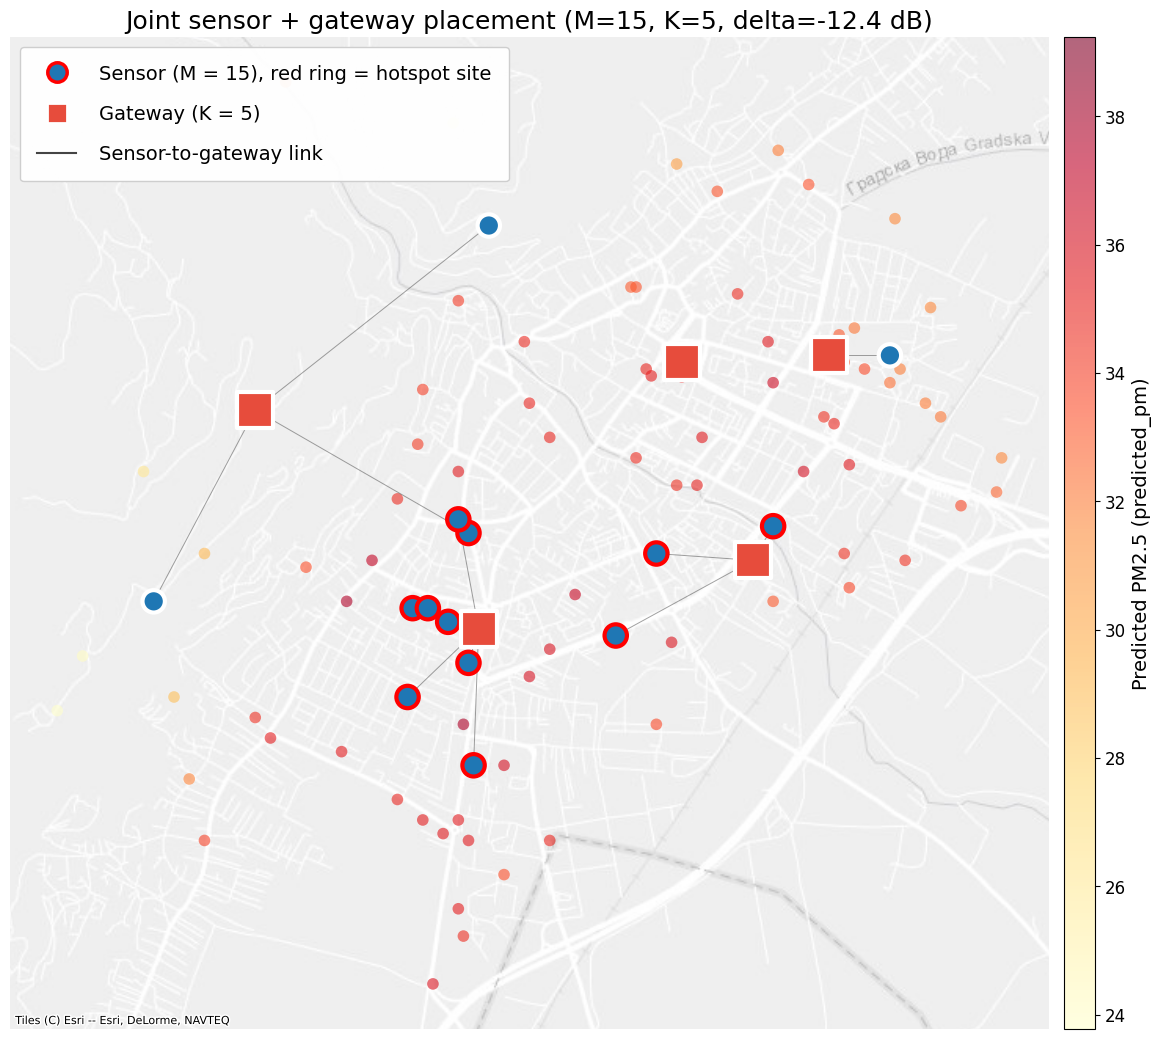

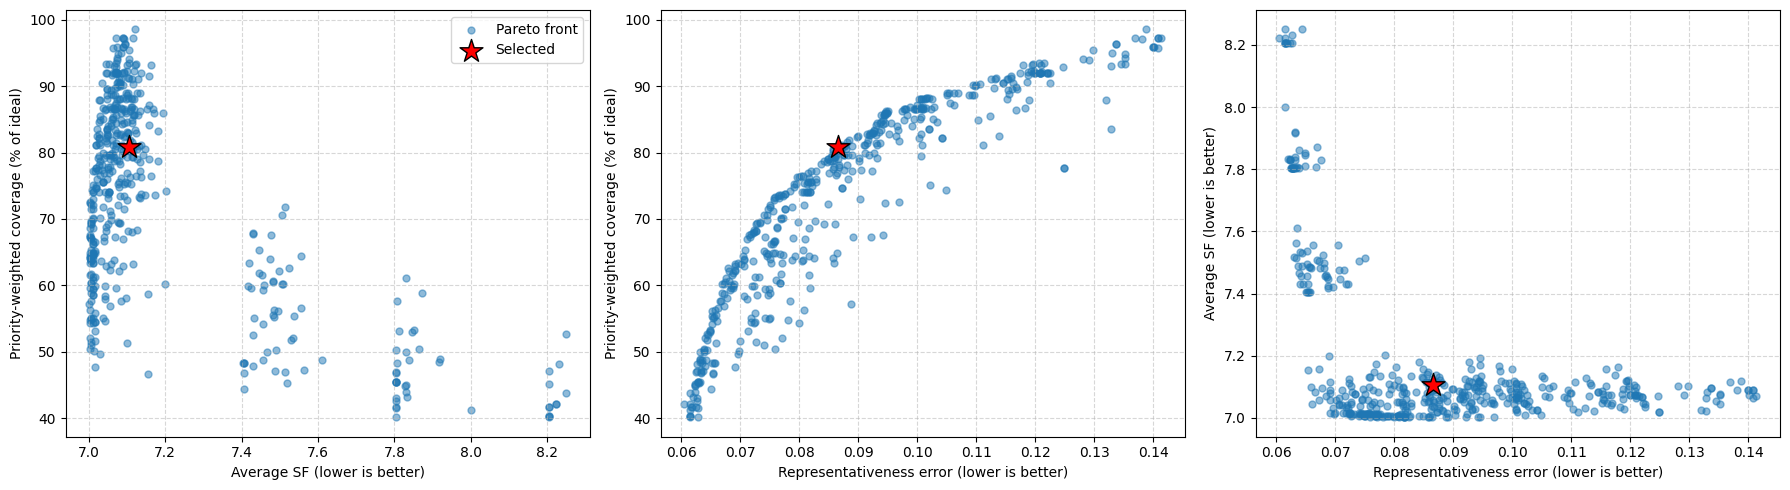

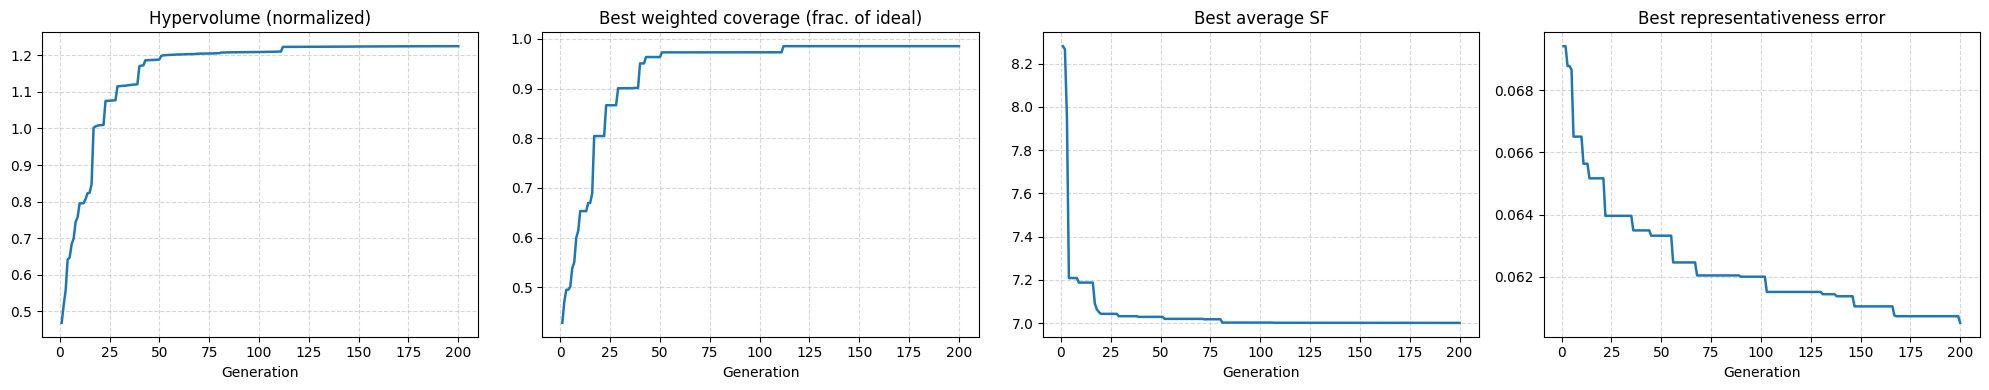

In [ ]:
# @title Plots: deployment map, Pareto front, convergence
tag = f"M{M}_K{K}_delta{DELTA_DB}_deltaS_{RUN_DELTA_SWEEP}_budgetS_{RUN_BUDGET_SWEEP}_geoW_{GEO_WEIGHT}_hotspotP_{USE_HOTSPOT_PROB}"
plot_deployment(ctx, S_best, G_best,
                f"Joint sensor + gateway placement (M={M}, K={K}, delta={DELTA_DB} dB)",
                save_stem=BASE_PATH + f"joint_deployment_{tag}")
plot_pareto(res, save_stem=BASE_PATH + f"joint_pareto_{tag}")
plot_convergence(res, save_stem=BASE_PATH + f"joint_convergence_{tag}")

In [ ]:
# @title Optional: robustness of the chosen topology to the radio-model offset (delta)
if RUN_DELTA_SWEEP:
    if not HAVE_RSSI:
        print("Skipped: needs link_mean_rssi_matrix.csv (see the first cell).")
    else:
        ref = optimize(make_context(DELTA_REF), M, K, pop=SWEEP_POP, gens=SWEEP_GENS)
        ref_g, ref_s = set(ids_of(ref["G"])), set(ids_of(ref["S"]))
        rows = []
        for d in DELTA_LIST:
            c = make_context(d)
            r = optimize(c, M, K, pop=SWEEP_POP, gens=SWEEP_GENS)
            g_set, s_set = set(ids_of(r["G"])), set(ids_of(r["S"]))
            row = describe(c, r["S"], r["G"], f"delta={d}")
            row["Same gateways as ref"] = (g_set == ref_g)
            row["Sensor overlap with ref (Jaccard)"] = round(len(s_set & ref_s) / len(s_set | ref_s), 2)
            row["Gateway sites"] = sorted(g_set)
            rows.append(row)
        delta_df = pd.DataFrame(rows).set_index("Method")
        display(delta_df)
        delta_df.to_csv(BASE_PATH + f"delta_sweep_M{M}_K{K}.csv")

,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled,Same gateways as ref,Sensor overlap with ref (Jaccard),Gateway sites
Method,,,,,,,,,,,,,,
delta=0,15,5,100.0,13,100.0,86.4,7.01,0.0943,409.0,2200.0,28.0-39.2,False,0.50,"[40, 55, 64, 7, 83]"
delta=-5,15,5,100.0,12,100.0,80.8,7.03,0.0848,364.0,1124.0,28.0-38.8,False,0.58,"[11, 12, 54, 55, 83]"
delta=-10,15,5,100.0,12,100.0,80.2,7.09,0.0854,371.0,1124.0,28.0-38.8,False,0.50,"[12, 20, 36, 54, 90]"
delta=-12.4,15,5,100.0,12,100.0,80.8,7.10,0.0866,374.0,1124.0,28.0-38.8,True,1.00,"[14, 31, 36, 64, 83]"
delta=-15,15,5,100.0,10,100.0,72.3,7.17,0.0828,381.0,1259.0,28.0-38.8,False,0.36,"[19, 2, 36, 55, 64]"
delta=-20,15,5,100.0,10,100.0,73.3,7.07,0.0835,376.0,1124.0,24.2-39.2,False,0.50,"[14, 23, 3, 40, 64]"


In [ ]:
# @title
200# @title Control: search noise vs radio-offset effect
SEEDS = [42, 7, 123]

def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b)

# (1) Same delta, different seeds: how much do the sets change from search noise alone?
c_ref = make_context(DELTA_REF)
runs = [optimize(c_ref, M, K, seed=s) for s in SEEDS]
rows = []
for a in range(len(runs)):
    for b in range(a + 1, len(runs)):
        rows.append({"Seed A": SEEDS[a], "Seed B": SEEDS[b],
                     "Gateway Jaccard": round(jaccard(ids_of(runs[a]["G"]), ids_of(runs[b]["G"])), 2),
                     "Sensor Jaccard": round(jaccard(ids_of(runs[a]["S"]), ids_of(runs[b]["S"])), 2)})
display(pd.DataFrame(rows))

# (2) One fixed plan (seed 42, chosen at DELTA_REF) evaluated under every delta, no re-optimization
base = runs[0]
rows = [describe(make_context(d), base["S"], base["G"], f"fixed plan @ delta={d}") for d in DELTA_LIST]
display(pd.DataFrame(rows).set_index("Method"))
print("Sensors :", ids_of(base["S"]))
print("Gateways:", ids_of(base["G"]))

,Seed A,Seed B,Gateway Jaccard,Sensor Jaccard
0,42,7,0.25,0.50
1,42,123,0.25,0.58
2,7,123,0.43,0.58


,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled
Method,,,,,,,,,,,
fixed plan @ delta=0,15,5,100.0,12,100.0,80.8,7.00,0.0866,374.0,1124.0,28.0-38.8
fixed plan @ delta=-5,15,5,100.0,12,100.0,80.8,7.02,0.0866,374.0,1124.0,28.0-38.8
fixed plan @ delta=-10,15,5,100.0,12,100.0,80.8,7.06,0.0866,374.0,1124.0,28.0-38.8
fixed plan @ delta=-12.4,15,5,100.0,12,100.0,80.8,7.10,0.0866,374.0,1124.0,28.0-38.8
fixed plan @ delta=-15,15,5,80.0,12,75.0,60.9,8.23,0.0866,374.0,1124.0,28.0-38.8
fixed plan @ delta=-20,15,5,73.3,12,66.7,54.1,8.63,0.0866,374.0,1124.0,28.0-38.8


Sensors : ['5', '8', '11', '15', '33', '39', '40', '41', '58', '60', '61', '63', '65', '87', '99']
Gateways: ['14', '31', '36', '64', '83']


In [ ]:
# @title Optional: effect of the budgets (how many gateways / sensors are needed)
if RUN_BUDGET_SWEEP:
    c = make_context(DELTA_DB)
    rows = []
    for k_ in K_LIST:
        if (not ALLOW_COLOCATION) and M + k_ > N: continue
        r = optimize(c, M, k_, pop=SWEEP_POP, gens=SWEEP_GENS)
        rows.append(describe(c, r["S"], r["G"], f"M={M}, K={k_}"))
    display(pd.DataFrame(rows).set_index("Method"))
    rows = []
    for m_ in M_LIST:
        if (not ALLOW_COLOCATION) and m_ + K > N: continue
        r = optimize(c, m_, K, pop=SWEEP_POP, gens=SWEEP_GENS)
        rows.append(describe(c, r["S"], r["G"], f"M={m_}, K={K}"))
    display(pd.DataFrame(rows).set_index("Method"))

,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled
Method,,,,,,,,,,,
"M=15, K=3",15,3,100.0,12,100.0,80.3,7.17,0.0901,405.0,1259.0,28.0-38.8
"M=15, K=4",15,4,100.0,10,100.0,75.5,7.14,0.0814,366.0,1124.0,28.0-38.8
"M=15, K=5",15,5,100.0,12,100.0,80.8,7.10,0.0866,374.0,1124.0,28.0-38.8
"M=15, K=6",15,6,100.0,12,100.0,81.5,7.09,0.0871,383.0,2125.0,28.0-39.2
"M=15, K=8",15,8,100.0,12,100.0,82.8,7.02,0.0897,393.0,2125.0,28.0-38.8
"M=15, K=10",15,10,100.0,13,100.0,86.1,7.03,0.0943,407.0,2125.0,28.0-38.8


,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled
Method,,,,,,,,,,,
"M=5, K=5",5,5,100.0,5,100.0,94.4,7.01,0.1508,588.0,2125.0,36.4-37.8
"M=10, K=5",10,5,100.0,9,100.0,86.2,7.14,0.1145,456.0,2125.0,33.2-38.8
"M=15, K=5",15,5,100.0,12,100.0,80.8,7.10,0.0866,374.0,1124.0,28.0-38.8
"M=20, K=5",20,5,100.0,15,100.0,80.5,7.15,0.0713,317.0,1124.0,28.0-38.8
"M=30, K=5",30,5,96.7,17,100.0,76.2,7.31,0.0471,210.0,751.0,23.8-38.8
"M=50, K=5",50,5,94.0,20,100.0,80.7,7.49,0.0279,131.0,668.0,23.8-38.8
"M=70, K=5",70,5,81.4,22,95.5,82.0,8.25,0.0096,44.0,576.0,23.8-39.2
"M=80, K=5",80,5,72.5,23,91.3,79.4,8.80,0.0049,23.0,277.0,23.8-39.2


In [ ]:
# @title Save the selected deployment
roles = np.where(S_best & G_best, "sensor+gateway", np.where(S_best, "sensor", np.where(G_best, "gateway", "unused")))
out = loc[["id", "latitude", "longitude"]].copy()
out["pm_pred"] = PM
out["hotspot"] = IS_HOT
out["role"] = roles
out_sel = out[out["role"] != "unused"].sort_values(["role", "id"])
out_sel.to_csv(BASE_PATH + f"joint_deployment_{tag}.csv", index=False)

summary = dict(M=M, K=K, delta_db=DELTA_DB, reliability_threshold=RELIABILITY_THRESHOLD,
               hotspot_quantile=HOTSPOT_QUANTILE, hotspot_gamma=HOTSPOT_GAMMA, geo_weight=GEO_WEIGHT,
               population=POPULATION_SIZE, generations=GENERATIONS, seed=SEED,
               sensors=ids_of(S_best), gateways=ids_of(G_best),
               metrics={k: (v if not isinstance(v, (np.integer, np.floating)) else float(v))
                        for k, v in describe(ctx, S_best, G_best, "Proposed").items()})
with open(BASE_PATH + f"joint_deployment_{tag}.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
display(out_sel)
print("Saved deployment CSV and JSON to", BASE_PATH)

,id,latitude,longitude,pm_pred,hotspot,role
13,14,42.001389,20.976111,34.934521,False,gateway
30,31,42.009444,20.972222,35.614313,True,gateway
35,36,41.998611,20.961111,39.237997,True,gateway
63,64,42.007500,20.948889,28.538227,False,gateway
82,83,42.009722,20.980278,33.564027,False,gateway
10,11,41.999444,20.957500,38.379612,True,sensor
14,15,42.002778,20.977222,36.409393,True,sensor
32,33,42.009167,20.972222,35.757932,True,sensor
38,39,41.999444,20.958333,38.293180,True,sensor
39,40,41.998889,20.959444,38.192345,True,sensor


Saved deployment CSV and JSON to /content/drive/MyDrive/Capstone/LoRa Placement/


In [ ]:
# @title Multi-seed stability: mean and range for the main deployment
# Uses the current configuration (DELTA_DB, GEO_WEIGHT, USE_HOTSPOT_PROB, M, K) as-is.
SEEDS_MULTI = [42, 7, 123, 11, 2026, 21, 50, 3407, 0, 1]

ctx_main = make_context(DELTA_DB)
seed_rows, seed_sets = [], []

for sd in SEEDS_MULTI:
    r = optimize(ctx_main, M, K, seed=sd)
    row = describe(ctx_main, r["S"], r["G"], f"seed {sd}")
    row["Seed"] = sd
    seed_rows.append(row)
    seed_sets.append((set(ids_of(r["S"])), set(ids_of(r["G"]))))

seed_df = pd.DataFrame(seed_rows).set_index("Seed")
display(seed_df)

# Summary: mean, min, max over seeds for the numeric metrics
num_cols = ["Covered sensors (%)", "Hotspot sensors (#)", "Hotspot sensors covered (%)",
            "Priority-wtd coverage (% of ideal)", "Avg SF", "Repr. error",
            "Mean dist to nearest sensor (m)", "Max dist to nearest sensor (m)"]
summary = pd.DataFrame({
    "mean": seed_df[num_cols].mean(),
    "min": seed_df[num_cols].min(),
    "max": seed_df[num_cols].max(),
}).round(3)
display(summary)

# Pairwise overlap of sites across seeds (how much the layout itself changes)
def _jac(a, b):
    return len(a & b) / len(a | b)

jac_rows = []
for a in range(len(SEEDS_MULTI)):
    for b in range(a + 1, len(SEEDS_MULTI)):
        jac_rows.append({"Seed A": SEEDS_MULTI[a], "Seed B": SEEDS_MULTI[b],
                         "Sensor Jaccard": round(_jac(seed_sets[a][0], seed_sets[b][0]), 2),
                         "Gateway Jaccard": round(_jac(seed_sets[a][1], seed_sets[b][1]), 2)})
jac_df = pd.DataFrame(jac_rows)
display(jac_df)
print(f"Sensor Jaccard: mean {jac_df['Sensor Jaccard'].mean():.2f}, range {jac_df['Sensor Jaccard'].min():.2f}-{jac_df['Sensor Jaccard'].max():.2f}")
print(f"Gateway Jaccard: mean {jac_df['Gateway Jaccard'].mean():.2f}, range {jac_df['Gateway Jaccard'].min():.2f}-{jac_df['Gateway Jaccard'].max():.2f}")

# Save for the paper
seed_df.to_csv(BASE_PATH + f"multiseed_M{M}_K{K}_delta{DELTA_DB}.csv")
summary.to_csv(BASE_PATH + f"multiseed_summary_M{M}_K{K}_delta{DELTA_DB}.csv")
jac_df.to_csv(BASE_PATH + f"multiseed_jaccard_M{M}_K{K}_delta{DELTA_DB}.csv", index=False)
print("Saved multi-seed tables to", BASE_PATH)

,Method,Sensors,Gateways,Covered sensors (%),Hotspot sensors (#),Hotspot sensors covered (%),Priority-wtd coverage (% of ideal),Avg SF,Repr. error,Mean dist to nearest sensor (m),Max dist to nearest sensor (m),PM range sampled
Seed,,,,,,,,,,,,
42,seed 42,15,5,100.0,12,100.0,80.8,7.10,0.0866,374.0,1124.0,28.0-38.8
7,seed 7,15,5,100.0,11,100.0,76.8,7.13,0.0814,362.0,1124.0,28.0-38.8
123,seed 123,15,5,100.0,11,100.0,77.7,7.15,0.0823,362.0,1124.0,28.0-38.8
11,seed 11,15,5,100.0,12,100.0,80.5,7.14,0.0870,377.0,1124.0,28.0-38.4
2026,seed 2026,15,5,100.0,11,100.0,75.6,7.12,0.0788,351.0,1124.0,28.0-39.2
21,seed 21,15,5,100.0,11,100.0,78.3,7.07,0.0840,380.0,1259.0,28.0-39.2
50,seed 50,15,5,100.0,11,100.0,76.3,7.13,0.0780,344.0,1124.0,28.0-39.2
3407,seed 3407,15,5,100.0,10,100.0,75.3,7.07,0.0808,362.0,1124.0,28.0-38.8
0,seed 0,15,5,100.0,11,100.0,76.8,7.08,0.0812,367.0,1124.0,28.0-39.2


,mean,min,max
Covered sensors (%),100.000,100.000,100.000
Hotspot sensors (#),11.200,10.000,12.000
Hotspot sensors covered (%),100.000,100.000,100.000
Priority-wtd coverage (% of ideal),77.860,75.300,80.800
Avg SF,7.114,7.070,7.150
Repr. error,0.083,0.078,0.087
Mean dist to nearest sensor (m),365.200,344.000,380.000
Max dist to nearest sensor (m),1137.500,1124.000,1259.000


,Seed A,Seed B,Sensor Jaccard,Gateway Jaccard
0,42,7,0.50,0.25
1,42,123,0.58,0.25
2,42,11,0.58,0.25
3,42,2026,0.50,0.25
4,42,21,0.43,0.25
5,42,50,0.50,0.25
6,42,3407,0.50,0.43
7,42,0,0.58,0.25
8,42,1,0.58,0.11
9,7,123,0.58,0.43


Sensor Jaccard: mean 0.48, range 0.30-0.67
Gateway Jaccard: mean 0.29, range 0.11-0.67
Saved multi-seed tables to /content/drive/MyDrive/Capstone/LoRa Placement/
